# ROP model evaluation

Loads the saved out-of-fold predictions and computes every metric and plot from them, so nothing here needs a GPU or the images.

Files this notebook expects next to it (written by the training notebook):
- `occ_df.csv`, `sev_df.csv` (one row per image: `y`, `fold`, `label`, `patient_id`; the row number in the first column)
- `oof_occ_{arch}.npy`, `oof_sev_{arch}.npy` for each architecture in `ARCHS`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)

# Loading the predictions

In [2]:
ARCHS = ["resnet18", "densenet121", "efficientnet_b0"]
OCC_CLASSES = ["Normal", "ROP"]
SEV_CLASSES = ["Mild ROP", "Moderate ROP", "Severe ROP"]

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# index_col=0 keeps the original row numbers, which is how the prediction arrays are indexed
occ_df = pd.read_csv("occ_df.csv", index_col=0)
sev_df = pd.read_csv("sev_df.csv", index_col=0)

# one array per architecture, shape (all images, n_classes). Rows that aren't part of a task are zeros
oof_occ = {arch: np.load(f"oof_occ_{arch}.npy") for arch in ARCHS}
oof_sev = {arch: np.load(f"oof_sev_{arch}.npy") for arch in ARCHS}

# ---- checks that the predictions line up with the dataframes (a misaligned index would silently give wrong metrics)
assert (occ_df.index == np.arange(len(occ_df))).all(), "occ_df should hold every image, in order"
outside_sev = np.setdiff1d(occ_df.index, sev_df.index)          # images that are not in the severity task
for arch in ARCHS:
    assert oof_occ[arch].shape == (len(occ_df), 2), f"{arch}: unexpected occurrence array shape"
    assert oof_sev[arch].shape == (len(occ_df), 3), f"{arch}: unexpected severity array shape"
    assert np.allclose(oof_occ[arch][occ_df.index].sum(axis=1), 1), f"{arch}: occurrence rows should be probabilities"
    assert np.allclose(oof_sev[arch][sev_df.index].sum(axis=1), 1), f"{arch}: severity rows should be probabilities"
    assert (oof_sev[arch][outside_sev] == 0).all(), f"{arch}: images outside the severity task should have no prediction"
print("predictions line up with the dataframes")
print("no patient is split between folds:", occ_df.groupby("patient_id")["fold"].nunique().max() == 1)
print("occurrence images:", len(occ_df), "| severity images:", len(sev_df))

predictions line up with the dataframes
no patient is split between folds: True
occurrence images: 1527 | severity images: 904


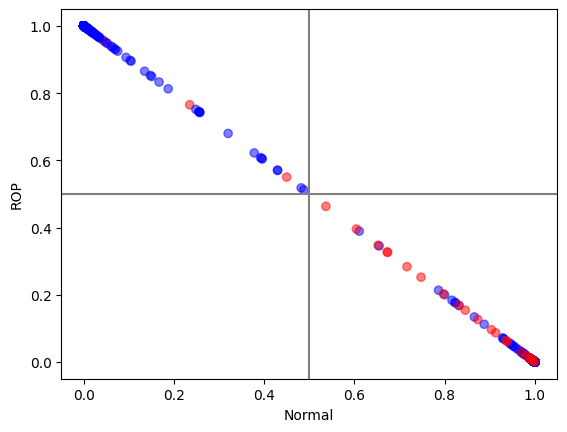

In [114]:
thresh = 0.5
densenet121_pred = pd.DataFrame(np.asarray(oof_occ["densenet121"]))
densenet121_pred.loc[densenet121_pred[1] >= thresh, "prediction"] = 1
densenet121_pred.loc[densenet121_pred[1] < thresh, "prediction"] = 0
for i in range(len(occ_df)):
    densenet121_pred.loc[i, "label"] = occ_df.loc[i, "ROP"]
(densenet121_pred["prediction"] == densenet121_pred["label"])
densenet121_pred.loc[(densenet121_pred["prediction"] == densenet121_pred["label"]), "true"] = "blue"
densenet121_pred.loc[(densenet121_pred["prediction"] != densenet121_pred["label"]), "true"] = "red"

plt.scatter(x=np.asarray(densenet121_pred[0]), y=np.asarray(densenet121_pred[1]), alpha=0.5, color=np.asarray(densenet121_pred["true"]))
plt.xlabel("Normal")
plt.ylabel("ROP")
plt.axvline(x=0.5, color="gray")
plt.axhline(y=0.5, color="gray")

# Metric functions

In [29]:
def report(df, oof, class_names):
    """Mean ± std across the 5 folds, pooled kappa, confusion matrix and the per-class report."""
    y, fold = df["y"].to_numpy(), df["fold"].to_numpy()
    pred = oof[df.index.to_numpy()].argmax(1)
    per_fold = lambda metric: [metric(y[fold == k], pred[fold == k]) for k in range(5)]
    accs, bals = per_fold(accuracy_score), per_fold(balanced_accuracy_score)
    f1s = per_fold(lambda a, b: f1_score(a, b, average="macro"))
    print(f"accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f} | balanced acc {np.mean(bals):.3f} ± {np.std(bals):.3f} | macro-F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
    print("pooled kappa:", round(cohen_kappa_score(y, pred), 3))

    labels = list(range(len(class_names)))
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=labels),
                      index=[f"actual {c}" for c in class_names],
                      columns=[f"pred {c}" for c in class_names])
    print(cm)
    print(classification_report(y, pred, labels=labels, target_names=class_names, digits=3, zero_division=0))

def occ_summary(oof):
    """Pooled out-of-fold metrics for the occurrence task."""
    y, p = occ_df["y"].to_numpy(), oof[occ_df.index.to_numpy()]
    pred = p.argmax(1)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"sensitivity (ROP recall)": tp / (tp + fn),
            "specificity (Normal recall)": tn / (tn + fp),
            "balanced acc": balanced_accuracy_score(y, pred),
            "macro-F1": f1_score(y, pred, average="macro"),
            "ROC-AUC": roc_auc_score(y, p[:, 1]),
            "PR-AUC": average_precision_score(y, p[:, 1])}

def sev_summary(oof):
    """Pooled out-of-fold metrics for the severity task."""
    y, pred = sev_df["y"].to_numpy(), oof[sev_df.index.to_numpy()].argmax(1)
    row = {"macro-F1": f1_score(y, pred, average="macro"),
           "balanced acc": balanced_accuracy_score(y, pred),
           "QWK": cohen_kappa_score(y, pred, weights="quadratic")}
    for name, recall in zip(SEV_CLASSES, recall_score(y, pred, average=None)):
        row[f"recall {name}"] = recall
    # of the wrong predictions, how many are only one severity class away
    row["errors one class off"] = (np.abs(pred - y) == 1).sum() / max((pred != y).sum(), 1)
    return row

In [30]:
# metric(true labels, probabilities) -> one number. Used for the per-fold tables and the bootstrap below
OCC_METRICS = {
    "balanced acc": lambda y, p: balanced_accuracy_score(y, p.argmax(1)),
    "macro-F1":     lambda y, p: f1_score(y, p.argmax(1), average="macro"),
    "ROC-AUC":      lambda y, p: roc_auc_score(y, p[:, 1]),
}
SEV_METRICS = {
    "balanced acc": lambda y, p: balanced_accuracy_score(y, p.argmax(1)),
    "macro-F1":     lambda y, p: f1_score(y, p.argmax(1), average="macro"),
    "QWK":          lambda y, p: cohen_kappa_score(y, p.argmax(1), weights="quadratic"),
}

def fold_table(df, oofs, metric):
    """One column per architecture, one row per fold, plus the mean and std across folds."""
    y, fold, idx = df["y"].to_numpy(), df["fold"].to_numpy(), df.index.to_numpy()
    table = pd.DataFrame({arch: [metric(y[fold == k], oofs[arch][idx][fold == k]) for k in range(5)] for arch in oofs})
    table.index = [f"fold {k}" for k in range(5)]
    table.loc["mean"], table.loc["std"] = table.iloc[:5].mean(), table.iloc[:5].std(ddof=0)
    return table

def bootstrap(df, oofs, metric, n_boot=1000, seed=0):
    """Resample whole patients (not images, since one infant's images aren't independent) with replacement.
    Every architecture is scored on the same resamples, so differences between them can be compared directly."""
    rng = np.random.default_rng(seed)
    y, idx = df["y"].to_numpy(), df.index.to_numpy()
    probs = {arch: oofs[arch][idx] for arch in oofs}
    rows_by_patient = df.groupby("patient_id").indices           # patient -> positions of their images in df
    patients = list(rows_by_patient)
    draws = {arch: [] for arch in oofs}
    for _ in range(n_boot):
        chosen = rng.integers(len(patients), size=len(patients))
        pos = np.concatenate([rows_by_patient[patients[i]] for i in chosen])
        for arch in oofs:
            draws[arch].append(metric(y[pos], probs[arch][pos]))
    return pd.DataFrame(draws)

def ci_table(draws, baseline="resnet18"):
    """Mean and 95% interval per architecture, and the difference from the baseline architecture."""
    rows = {}
    for arch in draws:
        lo, hi = draws[arch].quantile([0.025, 0.975])
        row = {"mean": round(draws[arch].mean(), 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]"}
        if arch != baseline:
            diff = draws[arch] - draws[baseline]
            dlo, dhi = diff.quantile([0.025, 0.975])
            row[f"difference vs {baseline}"] = f"{diff.mean():+.3f} [{dlo:+.3f}, {dhi:+.3f}]"
        rows[arch] = row
    return pd.DataFrame(rows).T

# Occurrence: comparison across architectures

In [31]:
# pooled over all out-of-fold predictions, at the default 0.5 decision threshold
print(pd.DataFrame({arch: occ_summary(oof_occ[arch]) for arch in ARCHS}).T.round(3))

# how much each metric moves between folds
for name, metric in OCC_METRICS.items():
    print(f"\n{name} per fold")
    print(fold_table(occ_df, oof_occ, metric).round(3))

                 sensitivity (ROP recall)  specificity (Normal recall)  \
resnet18                            0.971                        0.984   
densenet121                         0.976                        0.984   
efficientnet_b0                     0.959                        0.976   

                 balanced acc  macro-F1  ROC-AUC  PR-AUC  
resnet18                0.978     0.976    0.996   0.998  
densenet121             0.980     0.978    0.998   0.999  
efficientnet_b0         0.967     0.965    0.994   0.996  

balanced acc per fold
        resnet18  densenet121  efficientnet_b0
fold 0     0.978        0.984            0.969
fold 1     0.974        0.969            0.952
fold 2     0.981        0.992            0.978
fold 3     0.988        0.981            0.981
fold 4     0.967        0.974            0.957
mean       0.978        0.980            0.968
std        0.007        0.008            0.011

macro-F1 per fold
        resnet18  densenet121  efficientnet_b0
fo

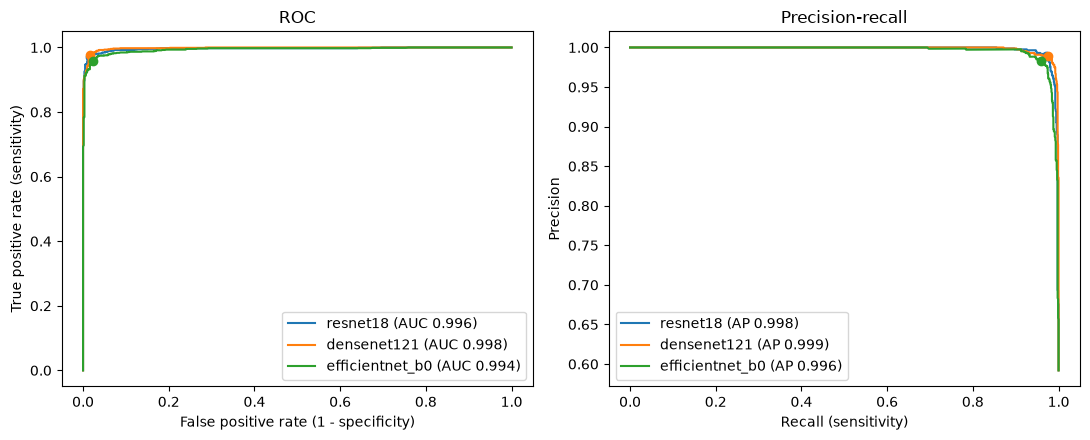

In [32]:
# ROC and precision-recall curves. The dot on each curve is the default 0.5 threshold (what the tables above use)
y, idx = occ_df["y"].to_numpy(), occ_df.index.to_numpy()
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
for arch in ARCHS:
    p = oof_occ[arch][idx, 1]                                   # predicted probability of ROP
    tn, fp, fn, tp = confusion_matrix(y, (p >= 0.5).astype(int)).ravel()
    fpr, tpr, _ = roc_curve(y, p)
    line, = ax_roc.plot(fpr, tpr, label=f"{arch} (AUC {roc_auc_score(y, p):.3f})")
    ax_roc.plot(fp / (fp + tn), tp / (tp + fn), "o", color=line.get_color())
    precision, recall, _ = precision_recall_curve(y, p)
    ax_pr.plot(recall, precision, color=line.get_color(), label=f"{arch} (AP {average_precision_score(y, p):.3f})")
    ax_pr.plot(tp / (tp + fn), tp / (tp + fp), "o", color=line.get_color())
ax_roc.set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (sensitivity)", title="ROC")
ax_pr.set(xlabel="Recall (sensitivity)", ylabel="Precision", title="Precision-recall")
# the curves overlap when AUC is near 1; zoom in with e.g. ax_roc.set_xlim(0, 0.2)
ax_roc.legend(loc="lower right"); ax_pr.legend(loc="lower left")
plt.tight_layout()
fig.savefig(FIG_DIR / "occ_roc_pr.png", dpi=200, bbox_inches="tight")
plt.show()

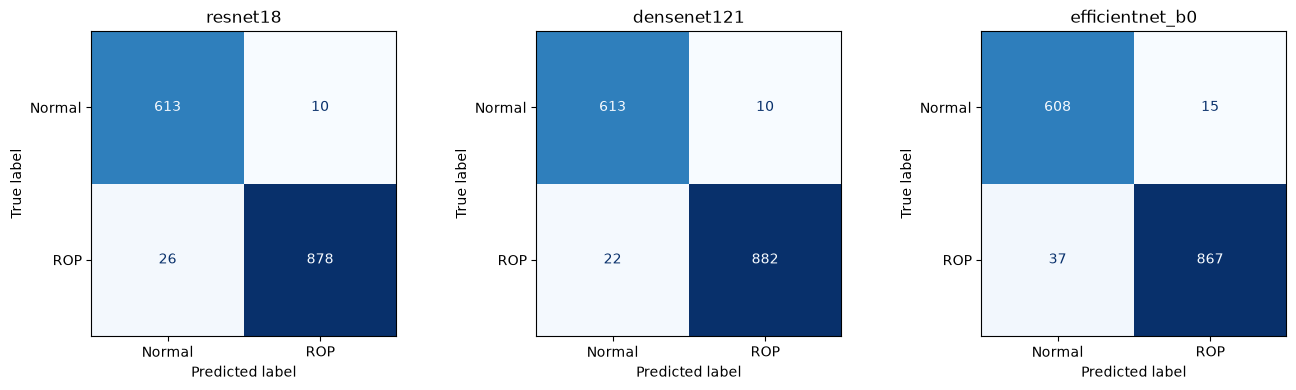

In [33]:
# confusion matrices side by side
fig, axes = plt.subplots(1, len(ARCHS), figsize=(4.5 * len(ARCHS), 4))
for ax, arch in zip(axes, ARCHS):
    pred = oof_occ[arch][occ_df.index.to_numpy()].argmax(1)
    ConfusionMatrixDisplay(confusion_matrix(occ_df["y"], pred), display_labels=OCC_CLASSES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(arch)
plt.tight_layout()
fig.savefig(FIG_DIR / "occ_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

# Occurrence: detailed reports

In [34]:
for arch in ARCHS:
    print(f"\n=============== {arch} ===============")
    report(occ_df, oof_occ[arch], OCC_CLASSES)


=============== resnet18 ===============
accuracy 0.976 ± 0.007 | balanced acc 0.978 ± 0.007 | macro-F1 0.976 ± 0.007
pooled kappa: 0.951
               pred Normal  pred ROP
actual Normal          613        10
actual ROP              26       878
              precision    recall  f1-score   support

      Normal      0.959     0.984     0.971       623
         ROP      0.989     0.971     0.980       904

    accuracy                          0.976      1527
   macro avg      0.974     0.978     0.976      1527
weighted avg      0.977     0.976     0.976      1527


=============== densenet121 ===============
accuracy 0.979 ± 0.008 | balanced acc 0.980 ± 0.008 | macro-F1 0.978 ± 0.008
pooled kappa: 0.957
               pred Normal  pred ROP
actual Normal          613        10
actual ROP              22       882
              precision    recall  f1-score   support

      Normal      0.965     0.984     0.975       623
         ROP      0.989     0.976     0.982       904

    ac

# Severity: comparison across architectures

In [35]:
# pooled over all out-of-fold predictions (ROP images only)
print(pd.DataFrame({arch: sev_summary(oof_sev[arch]) for arch in ARCHS}).T.round(3))
# what always predicting Mild ROP would score, to compare the accuracy against
print("majority-class accuracy:", round((sev_df["y"] == 0).mean(), 3))

for name, metric in SEV_METRICS.items():
    print(f"\n{name} per fold")
    print(fold_table(sev_df, oof_sev, metric).round(3))

                 macro-F1  balanced acc    QWK  recall Mild ROP  \
resnet18            0.799         0.777  0.781            0.937   
densenet121         0.842         0.820  0.823            0.953   
efficientnet_b0     0.806         0.791  0.775            0.908   

                 recall Moderate ROP  recall Severe ROP  errors one class off  
resnet18                       0.606              0.787                 0.953  
densenet121                    0.697              0.809                 0.940  
efficientnet_b0                0.610              0.854                 0.962  
majority-class accuracy: 0.635

balanced acc per fold
        resnet18  densenet121  efficientnet_b0
fold 0     0.724        0.792            0.736
fold 1     0.764        0.810            0.798
fold 2     0.864        0.843            0.805
fold 3     0.789        0.845            0.842
fold 4     0.739        0.806            0.770
mean       0.776        0.819            0.790
std        0.049        0.02

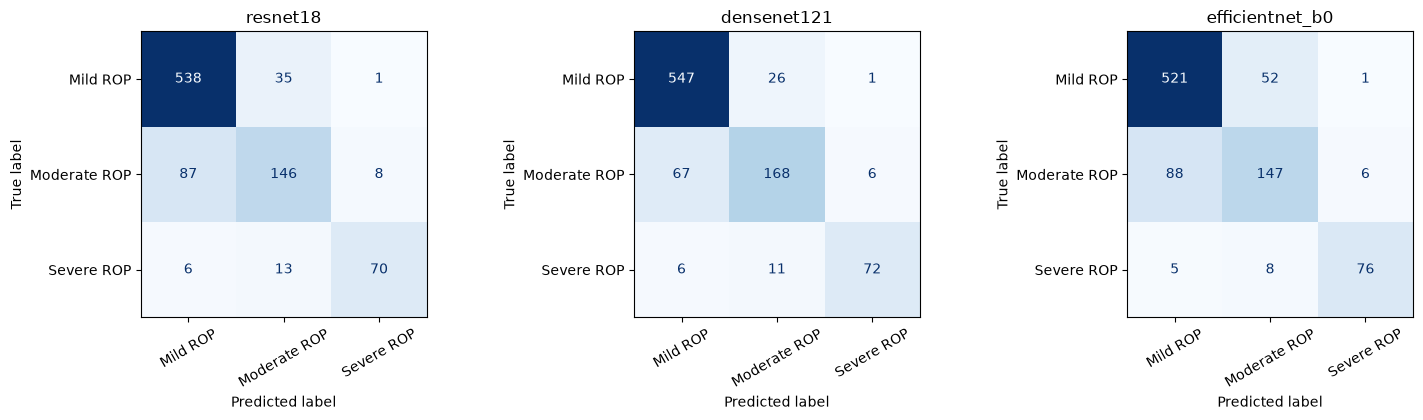

In [36]:
# confusion matrices side by side
fig, axes = plt.subplots(1, len(ARCHS), figsize=(5 * len(ARCHS), 4.3))
for ax, arch in zip(axes, ARCHS):
    pred = oof_sev[arch][sev_df.index.to_numpy()].argmax(1)
    ConfusionMatrixDisplay(confusion_matrix(sev_df["y"], pred, labels=[0, 1, 2]), display_labels=SEV_CLASSES).plot(
        ax=ax, colorbar=False, cmap="Blues", xticks_rotation=30)
    ax.set_title(arch)
plt.tight_layout()
fig.savefig(FIG_DIR / "sev_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

# Severity: detailed reports

In [37]:
for arch in ARCHS:
    print(f"\n=============== {arch} ===============")
    report(sev_df, oof_sev[arch], SEV_CLASSES)
    # which true stages land in which predicted severity (rows: actual stage, columns: predicted severity)
    pred = oof_sev[arch][sev_df.index.to_numpy()].argmax(1)
    print(pd.crosstab(sev_df["label"], pd.Series(pred, index=sev_df.index).map(dict(enumerate(SEV_CLASSES))),
                      rownames=["actual"], colnames=["predicted"]))


=============== resnet18 ===============
accuracy 0.834 ± 0.027 | balanced acc 0.776 ± 0.049 | macro-F1 0.797 ± 0.040
pooled kappa: 0.662
                     pred Mild ROP  pred Moderate ROP  pred Severe ROP
actual Mild ROP                538                 35                1
actual Moderate ROP             87                146                8
actual Severe ROP                6                 13               70
              precision    recall  f1-score   support

    Mild ROP      0.853     0.937     0.893       574
Moderate ROP      0.753     0.606     0.671       241
  Severe ROP      0.886     0.787     0.833        89

    accuracy                          0.834       904
   macro avg      0.830     0.777     0.799       904
weighted avg      0.829     0.834     0.828       904

predicted    Mild ROP  Moderate ROP  Severe ROP
actual                                         
Stage 1 ROP       232             4           0
Stage 2 ROP       306            31           1
Stag

# Two-stage pipeline

In [38]:
# Stage 1 (occurrence) decides whether an image reaches stage 2 (severity), so a missed ROP case never gets a severity.
# This uses the same architecture for both stages and covers the ROP images that have a severity label.
# (Normal images that stage 1 wrongly flags as ROP are not covered: the severity model never produced predictions for them.)

def pipeline_counts(occ_oof, sev_oof):
    """Rows: true severity. Columns: what the pipeline outputs."""
    idx, y = sev_df.index.to_numpy(), sev_df["y"].to_numpy()
    reaches_stage2 = occ_oof[idx].argmax(1) == 1
    output = np.where(reaches_stage2, sev_oof[idx].argmax(1) + 1, 0)   # 0 = missed (called Normal), 1-3 = Mild / Moderate / Severe
    counts = np.zeros((3, 4), dtype=int)
    np.add.at(counts, (y, output), 1)
    return pd.DataFrame(counts, index=[f"actual {c}" for c in SEV_CLASSES],
                        columns=["missed (called Normal)"] + [f"pred {c}" for c in SEV_CLASSES])

y = sev_df["y"].to_numpy()
for arch in ARCHS:
    counts = pipeline_counts(oof_occ[arch], oof_sev[arch])
    n = counts.sum(axis=1).to_numpy()
    summary = pd.DataFrame({
        "images": n,
        "missed by stage 1": counts.iloc[:, 0].to_numpy() / n,
        "severity-only recall": recall_score(y, oof_sev[arch][sev_df.index.to_numpy()].argmax(1), average=None),   # as if stage 1 were perfect
        "end-to-end recall": np.diag(counts.to_numpy()[:, 1:]) / n,                                                # right severity AND passed stage 1
    }, index=SEV_CLASSES)
    print(f"\n=============== {arch} ===============")
    print(counts)
    print(summary.round(3))
    print("end-to-end balanced accuracy:", round(summary["end-to-end recall"].mean(), 3))


=============== resnet18 ===============
                     missed (called Normal)  pred Mild ROP  pred Moderate ROP  \
actual Mild ROP                          22            517                 34   
actual Moderate ROP                       2             87                144   
actual Severe ROP                         2              5                 13   

                     pred Severe ROP  
actual Mild ROP                    1  
actual Moderate ROP                8  
actual Severe ROP                 69  
              images  missed by stage 1  severity-only recall  \
Mild ROP         574              0.038                 0.937   
Moderate ROP     241              0.008                 0.606   
Severe ROP        89              0.022                 0.787   

              end-to-end recall  
Mild ROP                  0.901  
Moderate ROP              0.598  
Severe ROP                0.775  
end-to-end balanced accuracy: 0.758

=============== densenet121 ===============

# Patient-level bootstrap confidence intervals

In [39]:
# 1000 resamples of patients, same resamples for every architecture. The intervals show uncertainty from which patients
# happen to be in the data. They do not include run-to-run variation from training (different seeds), so small
# differences between architectures should still be treated with caution.
print("Occurrence")
for name, metric in OCC_METRICS.items():
    print(f"\n{name}")
    print(ci_table(bootstrap(occ_df, oof_occ, metric)))

print("\n\nSeverity")
for name, metric in SEV_METRICS.items():
    print(f"\n{name}")
    print(ci_table(bootstrap(sev_df, oof_sev, metric)))

Occurrence

balanced acc
                  mean          95% CI   difference vs resnet18
resnet18         0.978  [0.970, 0.985]                      NaN
densenet121       0.98  [0.973, 0.987]  +0.002 [-0.006, +0.010]
efficientnet_b0  0.967  [0.958, 0.976]  -0.010 [-0.019, -0.001]

macro-F1
                  mean          95% CI   difference vs resnet18
resnet18         0.976  [0.967, 0.984]                      NaN
densenet121      0.978  [0.971, 0.986]  +0.003 [-0.006, +0.011]
efficientnet_b0  0.965  [0.955, 0.975]  -0.011 [-0.020, -0.001]

ROC-AUC
                  mean          95% CI   difference vs resnet18
resnet18         0.996  [0.994, 0.998]                      NaN
densenet121      0.998  [0.996, 0.999]  +0.002 [-0.000, +0.004]
efficientnet_b0  0.994  [0.990, 0.996]  -0.003 [-0.006, -0.000]


Severity

balanced acc
                  mean          95% CI   difference vs resnet18
resnet18         0.776  [0.741, 0.809]                      NaN
densenet121      0.819  [0.784, 0.8